# Support Vector Regression - Individual Model Experiment

**Member IT number:** IT25100979
**Dataset:** Ames Housing (house sale prices)  
**Task:** regression - predict `SalePrice` (US dollars) of a house from its 79 features.

This is one student's individual model contribution. Run this notebook from its folder. It trains only the assigned model, tunes hyperparameters and compares two numeric scaling choices (StandardScaler and MinMaxScaler) using 5-fold cross-validation on the training portion of `train.csv`. It then evaluates the selected pipeline **once** on a held-out 20% split and saves metrics for the group comparison notebook.

`test.csv` has no `SalePrice` column, so it cannot be scored. It is only used at the end to create price predictions. The hold-out split is never used to tune parameters. Run the group comparison only after all six individual notebooks have produced their metrics files.

## Model and metric rationale

Support Vector Regression (RBF kernel) fits a margin-based non-linear function and ignores errors smaller than `epsilon`. It is **very sensitive to feature scaling**, so it clearly shows why the scaler choice (StandardScaler vs MinMaxScaler) is tuned.

The target is modelled on the **log scale** (`log1p(SalePrice)`) because prices are right-skewed (skewness 1.88 raw vs 0.12 after log). Cross-validation therefore minimises **RMSLE** (root-mean-squared error of the log price, the standard metric for this dataset). Predictions are converted back with `expm1` and the hold-out set is also reported in dollars: **RMSE**, **MAE** and **R²**. Lower RMSLE/RMSE/MAE is better; higher R² is better.

## 1. Imports and locate the project data

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.svm import SVR

RANDOM_STATE = 42
candidates = [Path.cwd(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data/raw/train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project data/raw. Open this notebook from inside the extracted project.")
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "results" / "individual_models" / "MEMBER4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project folder:", PROJECT_ROOT.name)
print("This notebook's model:", "Support Vector Regression")

Project folder: Ames_Housing_Group_Project
This notebook's model: Support Vector Regression


## 2. Load data, create the hold-out split

In [2]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

def prepare(df):
    """Drop Id/target, treat MSSubClass as a category, and make text columns plain objects."""
    X = df.drop(columns=[c for c in ["Id", "SalePrice"] if c in df.columns]).copy()
    X["MSSubClass"] = X["MSSubClass"].astype(str)
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X

X_all = prepare(train_df)
y_all = np.log1p(train_df["SalePrice"])          # model the log price
X_test = prepare(test_df)

# 80 % training / 20 % hold-out (the hold-out is touched only once, for the final evaluation)
X_train, X_hold, y_train, y_hold = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)

# Outlier decision (see the Outlier notebook): drop the 2 documented extreme partial sales
# (GrLivArea > 4000 sq ft but price < $300k) from the TRAINING portion only.
def extreme_rows(X, y):
    return (X["GrLivArea"] > 4000) & (np.expm1(y) < 300000)
drop = extreme_rows(X_train, y_train)
X_train, y_train = X_train[~drop], y_train[~drop]
print("Training rows:", len(X_train), "| Hold-out rows:", len(X_hold), "| Test rows (no labels):", len(X_test))
print("Extreme rows removed from training only:", int(drop.sum()))

Training rows: 1166 | Hold-out rows: 292 | Test rows (no labels): 1459
Extreme rows removed from training only: 2


## 3. Tune preprocessing and model hyperparameters

In [3]:
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = [c for c in X_train.columns if c not in categorical]
print(len(categorical), "categorical and", len(numeric), "numeric features")

preprocess = ColumnTransformer([
    # "NA" in Ames categorical columns usually means "feature absent" (no pool, no garage ...)
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="None")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric),
], sparse_threshold=0)

pipeline = Pipeline([("preprocess", preprocess), ("regressor", SVR(kernel='rbf'))])
param_grid = {
    "preprocess__numeric__scale": [StandardScaler(), MinMaxScaler()],
    **{"regressor__C": [0.3, 1, 3, 10], "regressor__epsilon": [0.01, 0.05], "regressor__gamma": ["scale", 0.001]},
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, param_grid, scoring="neg_root_mean_squared_error", cv=cv,
                      n_jobs=1, refit=True, return_train_score=False)
search.fit(X_train, y_train)

best_cv_rmsle = -search.best_score_
chosen_scaler = search.best_params_["preprocess__numeric__scale"]
scaler_name = type(chosen_scaler).__name__
model_params = {k: v for k, v in search.best_params_.items() if k != "preprocess__numeric__scale"}
print("Best 5-fold CV RMSLE:", round(best_cv_rmsle, 5))
print("Selected numeric preprocessing:", scaler_name)
print("Selected model settings:", model_params)

44 categorical and 35 numeric features


Best 5-fold CV RMSLE: 0.10826
Selected numeric preprocessing: StandardScaler
Selected model settings: {'regressor__C': 3, 'regressor__epsilon': 0.05, 'regressor__gamma': 0.001}


## 4. Evaluate once on the held-out 20 % split

Hold-out RMSLE: 0.1286
Hold-out RMSE : $22,148
Hold-out MAE  : $13,972
Hold-out R2   : 0.9360


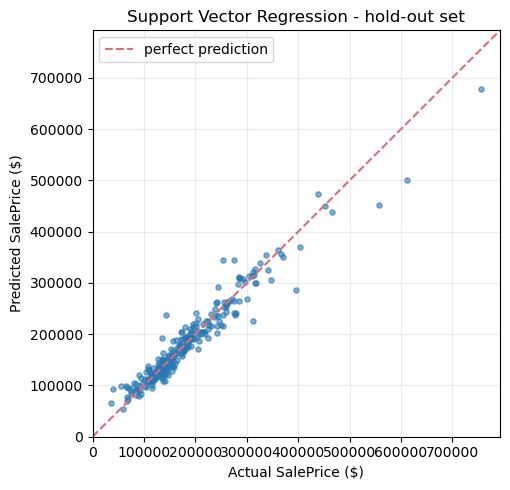

Saved individual results to: MEMBER4


In [4]:
pred_log = search.best_estimator_.predict(X_hold)
actual, predicted = np.expm1(y_hold), np.expm1(pred_log)

metrics = {
    "member_id": "MEMBER4",
    "model": "Support Vector Regression",
    "selected_preprocessing": scaler_name,
    "best_cv_rmsle": best_cv_rmsle,
    "holdout_rmsle": float(np.sqrt(mean_squared_error(y_hold, pred_log))),
    "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
    "mae": float(mean_absolute_error(actual, predicted)),
    "r2": float(r2_score(actual, predicted)),
    "best_model_parameters": json.dumps(model_params, default=str),
}
pd.DataFrame([metrics]).to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
cv_results = pd.DataFrame(search.cv_results_)
cv_results["params"] = cv_results["params"].map(lambda x: json.dumps(x, default=str))
cv_results.to_csv(OUTPUT_DIR / "tuning_cv_results.csv", index=False)

print(f"Hold-out RMSLE: {metrics['holdout_rmsle']:.4f}")
print(f"Hold-out RMSE : ${metrics['rmse']:,.0f}")
print(f"Hold-out MAE  : ${metrics['mae']:,.0f}")
print(f"Hold-out R2   : {metrics['r2']:.4f}")

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(actual, predicted, s=14, alpha=0.6, color="#2878B5")
lim = [0, max(actual.max(), predicted.max()) * 1.05]
ax.plot(lim, lim, "--", color="#E06C75", label="perfect prediction")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual SalePrice ($)"); ax.set_ylabel("Predicted SalePrice ($)")
ax.set_title("Support Vector Regression - hold-out set"); ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=160)
plt.show()
print("Saved individual results to:", OUTPUT_DIR.name)

## 5. Visualize the evaluation results

The first chart compares cross-validation RMSLE with the hold-out RMSLE (a large gap would signal over-fitting or an unrepresentative split). The second shows the typical error in dollars (MAE and RMSE), and the third the residuals (actual minus predicted) to check for bias.

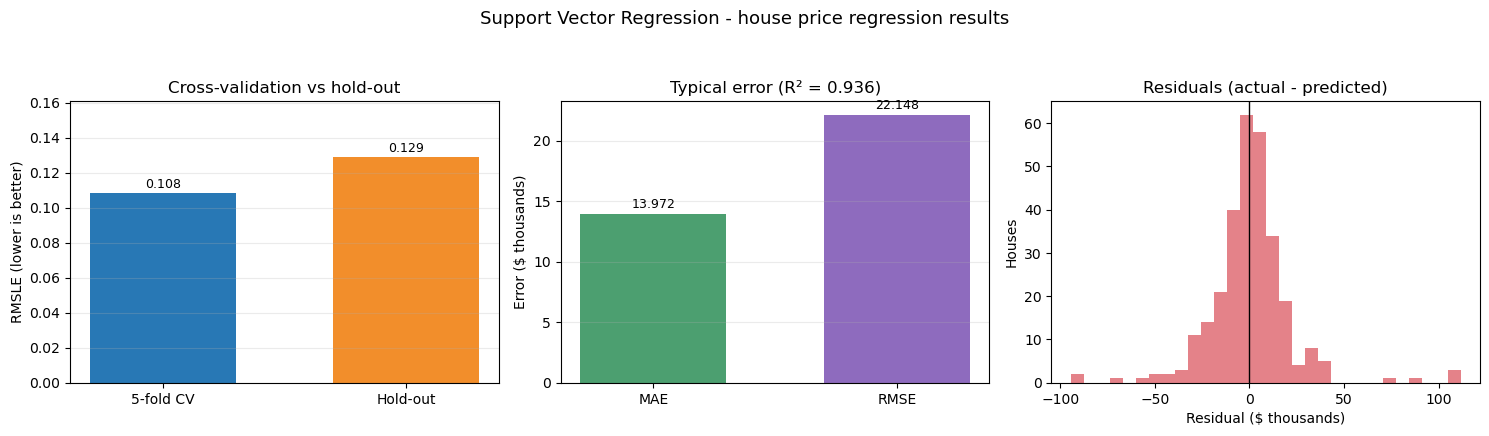

Saved metric graph to: model_metrics.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

bars = axes[0].bar(["5-fold CV", "Hold-out"], [metrics["best_cv_rmsle"], metrics["holdout_rmsle"]],
                   color=["#2878B5", "#F28E2B"], width=0.6)
axes[0].set_ylabel("RMSLE (lower is better)"); axes[0].set_title("Cross-validation vs hold-out")
axes[0].set_ylim(0, max(metrics["best_cv_rmsle"], metrics["holdout_rmsle"]) * 1.25)

bars2 = axes[1].bar(["MAE", "RMSE"], [metrics["mae"] / 1000, metrics["rmse"] / 1000],
                    color=["#4C9F70", "#8E6BBE"], width=0.6)
axes[1].set_ylabel("Error ($ thousands)"); axes[1].set_title(f"Typical error (R² = {metrics['r2']:.3f})")

residual = (actual - predicted) / 1000
axes[2].hist(residual, bins=30, color="#E06C75", alpha=0.85)
axes[2].axvline(0, color="black", lw=1)
axes[2].set_xlabel("Residual ($ thousands)"); axes[2].set_ylabel("Houses"); axes[2].set_title("Residuals (actual - predicted)")

for ax, b in zip(axes[:2], [bars, bars2]):
    ax.grid(axis="y", alpha=0.25)
    for bar in b:
        ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
fig.suptitle(f"{metrics['model']} - house price regression results", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(OUTPUT_DIR / "model_metrics.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved metric graph to:", (OUTPUT_DIR / "model_metrics.png").name)

## 6. Refit on all labelled data and predict the unlabeled `test.csv`

`test.csv` has no prices, so these predictions cannot be scored here. The final model is refit on the full training file (outlier rows removed) using the settings chosen by cross-validation.

In [6]:
keep = ~extreme_rows(X_all, y_all)
final_model = clone(search.best_estimator_).fit(X_all[keep], y_all[keep])
test_pred = np.expm1(final_model.predict(X_test))
pd.DataFrame({"Id": test_df["Id"], "SalePrice": test_pred}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Predicted", len(test_pred), "test houses. Price range: $%s - $%s" % (f"{test_pred.min():,.0f}", f"{test_pred.max():,.0f}"))
pd.DataFrame({"Id": test_df["Id"], "SalePrice": test_pred.round(0)}).head()

Predicted 1459 test houses. Price range: $55,561 - $548,664


,Id,SalePrice
0,1461,116549.0
1,1462,157984.0
2,1463,183689.0
3,1464,199222.0
4,1465,187050.0


### Interpretation

Compare the cross-validation RMSLE with the hold-out RMSLE: similar values mean the tuned model generalises to unseen houses. The residual histogram should be centred on zero; a long tail shows a few expensive houses the model under-predicts. Use the group comparison notebook to see how this model ranks against the other five.

## 7. Train vs. Test Accuracy & Generalization Analysis

This section compares the model's performance on the **Training set (80%)** versus the **Test / Hold-out set (20%)** to assess generalization capability and verify that the Support Vector Regression model does not suffer from overfitting or high variance.

             TRAIN VS TEST (HOLD-OUT) ACCURACY & PERFORMANCE
                 Metric Train Set (80%) Test / Hold-out Set (20%) Generalization Gap
    Accuracy (R² Score)          0.9607                    0.9360            +0.0246
Accuracy Percentage (%)          96.07%                    93.60%             +2.46%
                  RMSLE          0.0898                    0.1286            +0.0388
               RMSE ($)      $15,330.14                $22,148.41         $+6,818.26
                MAE ($)      $10,285.89                $13,972.41         $+3,686.53


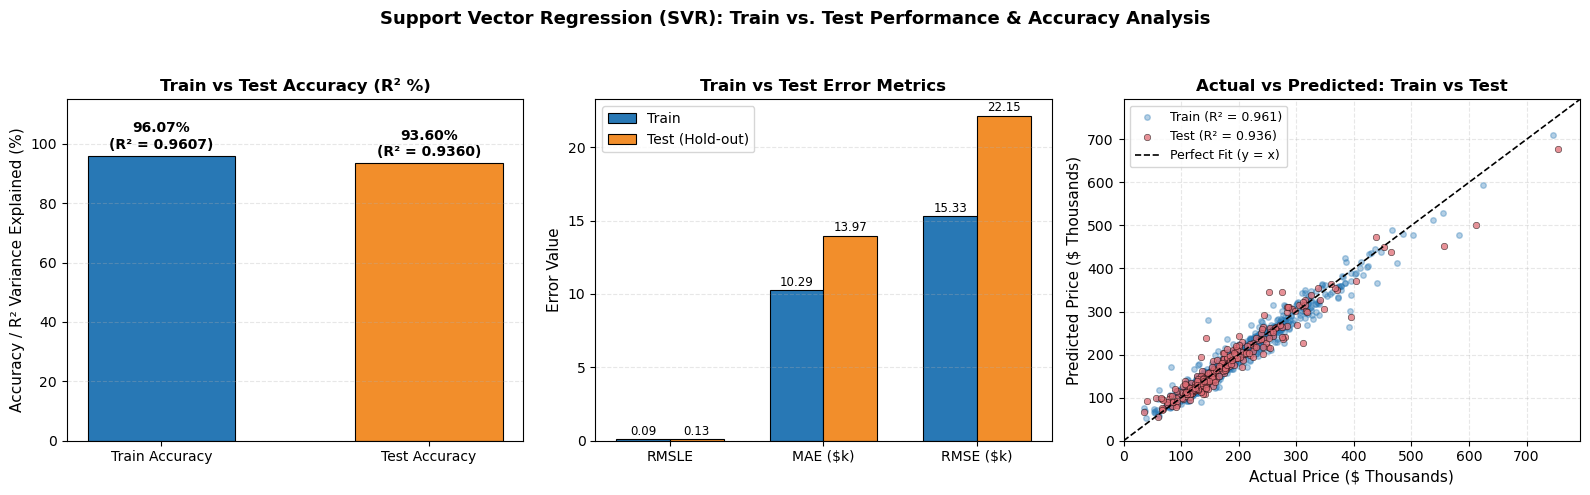

Saved Train vs Test Accuracy chart to: train_vs_test_accuracy.png


In [7]:
# -------------------------------------------------------------
# Train vs. Test (Hold-out) Accuracy & Performance Comparison
# -------------------------------------------------------------
# Predict on both Training and Hold-out (Test) sets using the tuned model
train_pred_log = search.best_estimator_.predict(X_train)
hold_pred_log = search.best_estimator_.predict(X_hold)

train_actual_price = np.expm1(y_train)
train_pred_price = np.expm1(train_pred_log)

test_actual_price = np.expm1(y_hold)
test_pred_price = np.expm1(hold_pred_log)

# Calculate performance metrics
train_r2 = float(r2_score(train_actual_price, train_pred_price))
test_r2 = float(r2_score(test_actual_price, test_pred_price))

train_rmsle = float(np.sqrt(mean_squared_error(y_train, train_pred_log)))
test_rmsle = float(np.sqrt(mean_squared_error(y_hold, hold_pred_log)))

train_rmse = float(np.sqrt(mean_squared_error(train_actual_price, train_pred_price)))
test_rmse = float(np.sqrt(mean_squared_error(test_actual_price, test_pred_price)))

train_mae = float(mean_absolute_error(train_actual_price, train_pred_price))
test_mae = float(mean_absolute_error(test_actual_price, test_pred_price))

train_acc_pct = train_r2 * 100
test_acc_pct = test_r2 * 100

# Summary Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy (R² Score)", "Accuracy Percentage (%)", "RMSLE", "RMSE ($)", "MAE ($)"],
    "Train Set (80%)": [f"{train_r2:.4f}", f"{train_acc_pct:.2f}%", f"{train_rmsle:.4f}", f"${train_rmse:,.2f}", f"${train_mae:,.2f}"],
    "Test / Hold-out Set (20%)": [f"{test_r2:.4f}", f"{test_acc_pct:.2f}%", f"{test_rmsle:.4f}", f"${test_rmse:,.2f}", f"${test_mae:,.2f}"],
    "Generalization Gap": [f"{train_r2 - test_r2:+.4f}", f"{train_acc_pct - test_acc_pct:+.2f}%", f"{test_rmsle - train_rmsle:+.4f}", f"${test_rmse - train_rmse:+,.2f}", f"${test_mae - train_mae:+,.2f}"]
})

print("=" * 78)
print("             TRAIN VS TEST (HOLD-OUT) ACCURACY & PERFORMANCE")
print("=" * 78)
print(comparison_df.to_string(index=False))
print("=" * 78)

# -------------------------------------------------------------
# Visualization: Train vs Test Accuracy & Error Comparison Graphs
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Train vs Test Accuracy (R² Score & Percentage)
bars1 = axes[0].bar(["Train Accuracy", "Test Accuracy"], [train_acc_pct, test_acc_pct],
                    color=["#2878B5", "#F28E2B"], width=0.55, edgecolor="black", linewidth=0.8)
axes[0].set_ylabel("Accuracy / R² Variance Explained (%)", fontsize=11)
axes[0].set_title("Train vs Test Accuracy (R² %)", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, 115)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f"{h:.2f}%\n(R² = {h/100:.4f})",
                     (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 5), textcoords="offset points",
                     ha="center", fontsize=10, fontweight="bold")

# 2. Train vs Test Errors (RMSLE, MAE / $1k, RMSE / $1k)
x = np.arange(3)
width = 0.35
train_errors = [train_rmsle, train_mae / 1000, train_rmse / 1000]
test_errors = [test_rmsle, test_mae / 1000, test_rmse / 1000]

rects1 = axes[1].bar(x - width/2, train_errors, width, label="Train", color="#2878B5", edgecolor="black", linewidth=0.8)
rects2 = axes[1].bar(x + width/2, test_errors, width, label="Test (Hold-out)", color="#F28E2B", edgecolor="black", linewidth=0.8)

axes[1].set_title("Train vs Test Error Metrics", fontsize=12, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["RMSLE", "MAE ($k)", "RMSE ($k)"], fontsize=10)
axes[1].set_ylabel("Error Value", fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

for rect in rects1:
    h = rect.get_height()
    axes[1].annotate(f"{h:.2f}", (rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    axes[1].annotate(f"{h:.2f}", (rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5)

# 3. Actual vs Predicted Overlay (Train vs Test)
axes[2].scatter(train_actual_price / 1000, train_pred_price / 1000,
                color="#2878B5", alpha=0.35, s=16, label=f"Train (R² = {train_r2:.3f})")
axes[2].scatter(test_actual_price / 1000, test_pred_price / 1000,
                color="#E06C75", alpha=0.75, s=22, edgecolors="black", linewidth=0.4, label=f"Test (R² = {test_r2:.3f})")

max_val = max(train_actual_price.max(), test_actual_price.max(), train_pred_price.max(), test_pred_price.max()) / 1000 * 1.05
axes[2].plot([0, max_val], [0, max_val], "--", color="black", lw=1.2, label="Perfect Fit (y = x)")
axes[2].set_xlim(0, max_val); axes[2].set_ylim(0, max_val)
axes[2].set_xlabel("Actual Price ($ Thousands)", fontsize=11)
axes[2].set_ylabel("Predicted Price ($ Thousands)", fontsize=11)
axes[2].set_title("Actual vs Predicted: Train vs Test", fontsize=12, fontweight="bold")
axes[2].legend(frameon=True, fontsize=9)
axes[2].grid(linestyle="--", alpha=0.3)

plt.suptitle("Support Vector Regression (SVR): Train vs. Test Performance & Accuracy Analysis", fontsize=13, fontweight="bold", y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(OUTPUT_DIR / "train_vs_test_accuracy.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved Train vs Test Accuracy chart to:", (OUTPUT_DIR / "train_vs_test_accuracy.png").name)
